# Assignment 7
Due Oct. 28

Yazdan Zinati 
260928077   

Dataset with brain atlas A: use the Oasis dataset for classification of male and female
individuals based on brain scans.

In [1]:
import numpy as np
from nilearn import datasets
from nilearn.input_data import NiftiLabelsMasker
from nilearn.image import index_img
import nibabel as nib


def fetch_oasis_dataset(n_rois, debug=False):
    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
    yeo = datasets.fetch_atlas_schaefer_2018(
        n_rois=n_rois
    )  # this needs to be modified for some tasks
    # print(
    #     "%i regions found in this atlas"
    #     % (len(np.unique(nib.load(yeo.maps).get_fdata().ravel())) - 1)
    # )
    masker = NiftiLabelsMasker(
        labels_img=yeo.maps, standardize=True, memory="nilearn_cache"
    )
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = np.array(
        brain_data.ext_vars.mf == "F", dtype=int
    )  # gives 1 for females and 0 for males

    if debug:
        print(
            "Fetched dataset.\n" "input variables shape:",
            input_variables.shape,
            "\n",
            "output variable shape",
            output_variable.shape,
        )
    return input_variables, output_variable

Task 1- Use LogisticRegression(penalty=’l2’, C=1.0) to fit separate classification models
based on 100 brain regions of interest (n_rois=100). Perform dimensionality reduction on
the training split via a) k-means clustering (n_clusters), b) GMMs (n_clusters), c) PCA
(n_components), and d) ICA (n_components) to transform the original 100 input variables
into k=1,2,3,…,10 latent pattern projections. Next, evaluate each fitted LogReg model on
the unseen structural brain scans and retrieve classification accuracy. Do this prediction
problem based on using 5-fold (KFold) cross-validation. Plot the classification accuracy on
the test set vs k (k on the x-axis, test classification accuracy on the y axis; one line for each
of the 4 dimensionality reduction methods).

Fetched dataset.
input variables shape: (100, 100) 
 output variable shape (100,)


/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE5

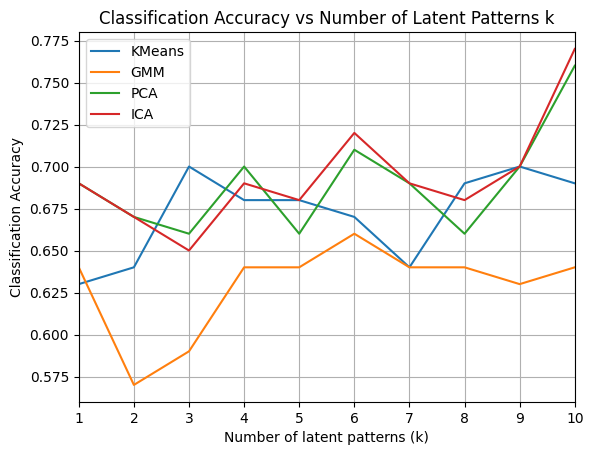

In [2]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA, FastICA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

splits_n = 5
n_rois = 100
ks = range(1, 11)
k_means_res, gmm_res, pca_res, ica_res = [], [], [], []

input_variables, output_variable = fetch_oasis_dataset(n_rois=n_rois, debug=True)
kf = KFold(n_splits=splits_n, shuffle=True)

for k in ks:
    k_means_acc, gmm_acc, pca_acc, ica_acc = [], [], [], []

    for train_index, test_index in kf.split(input_variables):
        X_train, y_train = input_variables[train_index], output_variable[train_index]
        X_test, y_test = input_variables[test_index], output_variable[test_index]

        lr = LogisticRegression(penalty="l2", C=1.0)

        km = KMeans(n_clusters=k)
        lr.fit(km.fit_transform(X_train), y_train)
        k_means_acc.append(accuracy_score(y_test, lr.predict(km.transform(X_test))))

        gmm = GaussianMixture(n_components=k)
        lr.fit(gmm.fit_predict(X_train).reshape(-1, 1), y_train)
        gmm_acc.append(
            accuracy_score(y_test, lr.predict(gmm.predict(X_test).reshape(-1, 1)))
        )

        pca = PCA(n_components=k)
        lr.fit(pca.fit_transform(X_train), y_train)
        pca_acc.append(accuracy_score(y_test, lr.predict(pca.transform(X_test))))

        ica = FastICA(n_components=k, random_state=42)
        lr.fit(ica.fit_transform(X_train), y_train)
        ica_acc.append(accuracy_score(y_test, lr.predict(ica.transform(X_test))))

    k_means_res.append(np.mean(k_means_acc))
    gmm_res.append(np.mean(gmm_acc))
    pca_res.append(np.mean(pca_acc))
    ica_res.append(np.mean(ica_acc))

plt.figure()
plt.plot(list(ks), k_means_res, label="KMeans")
plt.plot(list(ks), gmm_res, label="GMM")
plt.plot(list(ks), pca_res, label="PCA")
plt.plot(list(ks), ica_res, label="ICA")
plt.xlabel("Number of latent patterns (k)")
plt.ylabel("Classification Accuracy")
plt.title("Classification Accuracy vs Number of Latent Patterns k")
plt.legend()
plt.grid(True)
plt.xticks(list(ks))
plt.xlim([1, 10])
plt.show()


Task 2- Same as 1 but use k=5 clusters/components and train a different
LogisticRegression model on each atlas resolution (n_rois=100,200,…,1000). Plot the atlas
resolution on the x-axis and test classification accuracy on the y-axis, and one line for each
dimensionality reduction method.

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE5

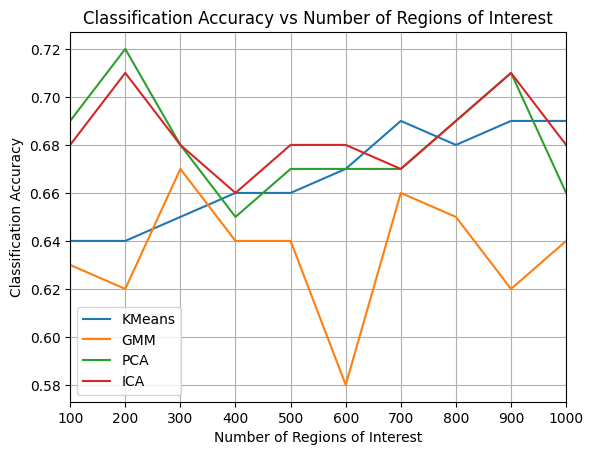

In [3]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA, FastICA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

splits_n = 5
n_rois = range(100, 1100, 100)
k = 5
k_means_res, gmm_res, pca_res, ica_res = [], [], [], []

for n_roi in n_rois:
    k_means_acc, gmm_acc, pca_acc, ica_acc = [], [], [], []

    input_variables, output_variable = fetch_oasis_dataset(n_rois=n_roi)
    kf = KFold(n_splits=splits_n, shuffle=True)


    for train_index, test_index in kf.split(input_variables):
        X_train, y_train = input_variables[train_index], output_variable[train_index]
        X_test, y_test = input_variables[test_index], output_variable[test_index]

        lr = LogisticRegression(penalty="l2", C=1.0)

        km = KMeans(n_clusters=k)
        lr.fit(km.fit_transform(X_train), y_train)
        k_means_acc.append(accuracy_score(y_test, lr.predict(km.transform(X_test))))

        gmm = GaussianMixture(n_components=k)
        lr.fit(gmm.fit_predict(X_train).reshape(-1, 1), y_train)
        gmm_acc.append(
            accuracy_score(y_test, lr.predict(gmm.predict(X_test).reshape(-1, 1)))
        )

        pca = PCA(n_components=k)
        lr.fit(pca.fit_transform(X_train), y_train)
        pca_acc.append(accuracy_score(y_test, lr.predict(pca.transform(X_test))))

        ica = FastICA(n_components=k, random_state=42)
        lr.fit(ica.fit_transform(X_train), y_train)
        ica_acc.append(accuracy_score(y_test, lr.predict(ica.transform(X_test))))

    k_means_res.append(np.mean(k_means_acc))
    gmm_res.append(np.mean(gmm_acc))
    pca_res.append(np.mean(pca_acc))
    ica_res.append(np.mean(ica_acc))

plt.figure()
plt.plot(list(n_rois), k_means_res, label="KMeans")
plt.plot(list(n_rois), gmm_res, label="GMM")
plt.plot(list(n_rois), pca_res, label="PCA")
plt.plot(list(n_rois), ica_res, label="ICA")
plt.xlabel("Number of Regions of Interest")
plt.ylabel("Classification Accuracy")
plt.title("Classification Accuracy vs Number of Regions of Interest")
plt.legend()
plt.grid(True)
plt.xticks(list(n_rois))
plt.xlim([100, 1000])
plt.show()


Task 3- Combining knowledge from task 1 and 2, plot a heatmap that shows the atlas
resolution (100-1000) on the x axis and the cluster/component number (10 choices) on the y
axis, while the color of the tiles/cubes of the heatmap shows the final out-of-sample cross-
validation estimate (classification accuracy). Since there are 4 different dimensionality
reduction methods, there should be 4 such plots; one resolution-by-factor-num ber plot per
clustering/decomposition method. Do another such 4 plots, but based on the average
training set prediction accuracy (across the 5 training sets). You should have 8 plots overall,
2 for each reduction method.

outer loop:   0%|          | 0/10 [00:00<?, ?it/s]

outer loop:  10%|█         | 1/10 [02:43<24:33, 163.73s/it]/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
outer loop:  20%|██        | 2/10 [05:40<22:53, 171.69s/it]/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
outer loop:  30%|███       | 3/10 [08:43<20:34, 176.41s/it]/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastIC

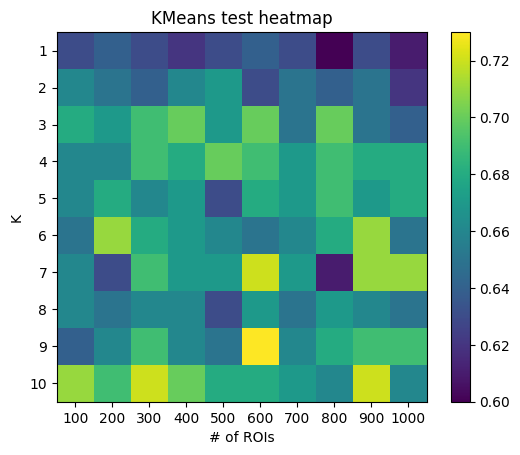

/tmp/ipykernel_34264/2661742294.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(n_rois))
/tmp/ipykernel_34264/2661742294.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(ks))


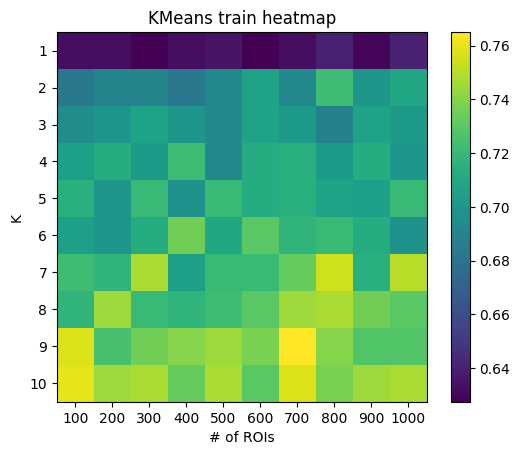

/tmp/ipykernel_34264/2661742294.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(n_rois))
/tmp/ipykernel_34264/2661742294.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(ks))


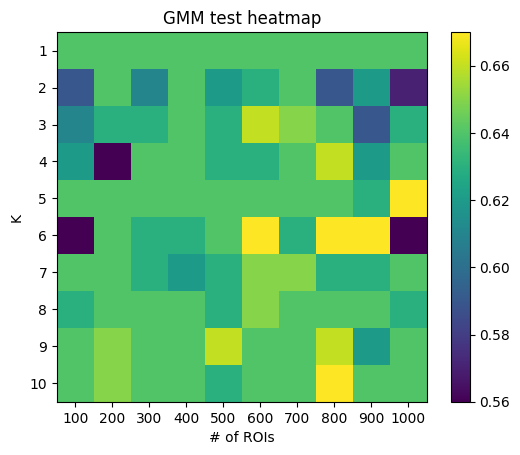

/tmp/ipykernel_34264/2661742294.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(n_rois))
/tmp/ipykernel_34264/2661742294.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(ks))


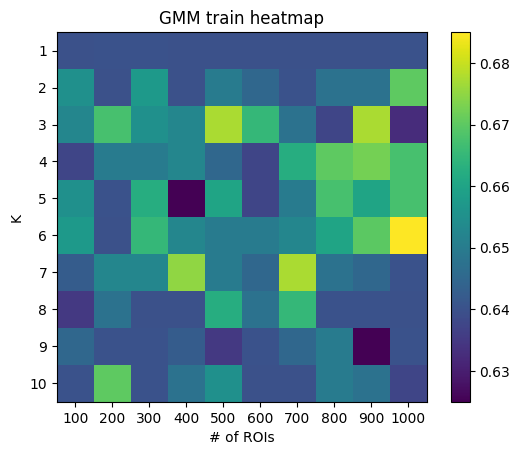

/tmp/ipykernel_34264/2661742294.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(n_rois))
/tmp/ipykernel_34264/2661742294.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(ks))


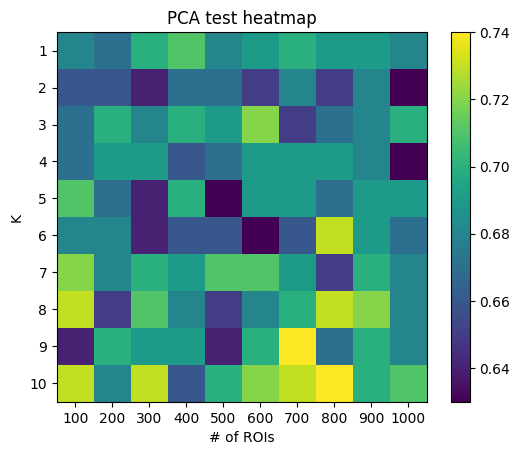

/tmp/ipykernel_34264/2661742294.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(n_rois))
/tmp/ipykernel_34264/2661742294.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(ks))


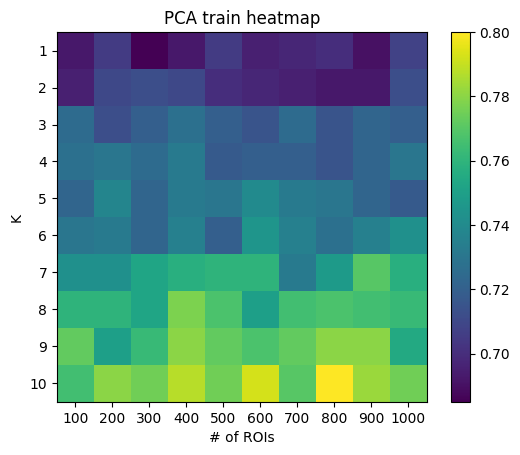

/tmp/ipykernel_34264/2661742294.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(n_rois))
/tmp/ipykernel_34264/2661742294.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(ks))


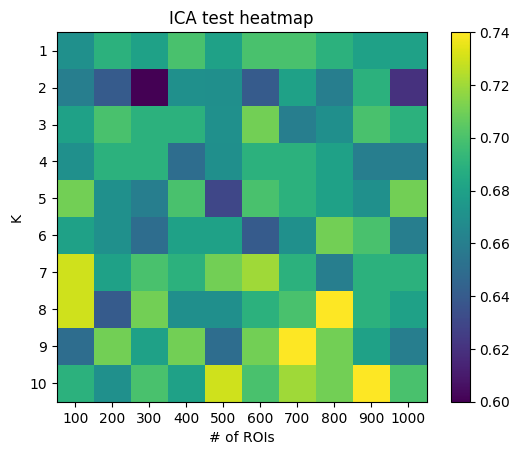

/tmp/ipykernel_34264/2661742294.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(n_rois))
/tmp/ipykernel_34264/2661742294.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(ks))


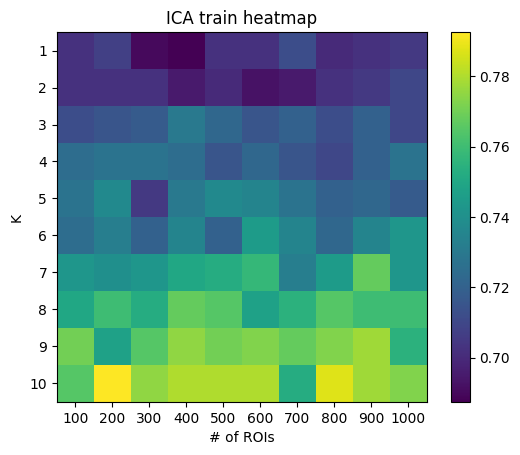

In [4]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA, FastICA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import tqdm

splits_n = 5
n_rois = range(100, 1100, 100)
ks = range(1, 11)

k_means_res, gmm_res, pca_res, ica_res = [], [], [], []
k_means_res_train, gmm_res_train, pca_res_train, ica_res_train = [], [], [], []

for k in tqdm.tqdm(ks, desc="outer loop"):
    for n_roi in tqdm.tqdm(n_rois, desc="middle loop"):
        input_variables, output_variable = fetch_oasis_dataset(n_rois=n_roi)
        kf = KFold(n_splits=splits_n, shuffle=True)

        k_means_acc, gmm_acc, pca_acc, ica_acc = [], [], [], []
        k_means_acc_train, gmm_acc_train, pca_acc_train, ica_acc_train = [], [], [], []
        for train_index, test_index in kf.split(input_variables):
            X_train, y_train = (
                input_variables[train_index],
                output_variable[train_index],
            )
            X_test, y_test = input_variables[test_index], output_variable[test_index]

            lr = LogisticRegression(penalty="l2", C=1.0)

            km = KMeans(n_clusters=k)
            lr.fit(km.fit_transform(X_train), y_train)
            k_means_acc.append(accuracy_score(y_test, lr.predict(km.transform(X_test))))
            k_means_acc_train.append(
                accuracy_score(y_train, lr.predict(km.transform(X_train)))
            )

            gmm = GaussianMixture(n_components=k)
            lr.fit(gmm.fit_predict(X_train).reshape(-1, 1), y_train)
            gmm_acc.append(
                accuracy_score(y_test, lr.predict(gmm.predict(X_test).reshape(-1, 1)))
            )
            gmm_acc_train.append(accuracy_score(y_train, lr.predict(gmm.predict(X_train).reshape(-1, 1))))

            pca = PCA(n_components=k)
            lr.fit(pca.fit_transform(X_train), y_train)
            pca_acc.append(accuracy_score(y_test, lr.predict(pca.transform(X_test))))
            pca_acc_train.append(accuracy_score(y_train, lr.predict(pca.transform(X_train))))

            ica = FastICA(n_components=k, random_state=42)
            lr.fit(ica.fit_transform(X_train), y_train)
            ica_acc.append(accuracy_score(y_test, lr.predict(ica.transform(X_test))))
            ica_acc_train.append(accuracy_score(y_train, lr.predict(ica.transform(X_train))))

        k_means_res.append(np.mean(k_means_acc))
        gmm_res.append(np.mean(gmm_acc))
        pca_res.append(np.mean(pca_acc))
        ica_res.append(np.mean(ica_acc))
        k_means_res_train.append(np.mean(k_means_acc_train))
        gmm_res_train.append(np.mean(gmm_acc_train))
        pca_res_train.append(np.mean(pca_acc_train))
        ica_res_train.append(np.mean(ica_acc_train))

def plot_square_heatmap(data, title):
    # Determine the size of the square matrix
    n = int(len(data) ** 0.5)
    
    if n * n != len(data):
        raise ValueError("The list length must be a perfect square")
    
    # Reshape data into an n x n matrix
    matrix = np.array(data).reshape(n, n)
    # Plot heatmap
    ax = plt.axes() 
    ax.set_xticklabels(list(n_rois))
    ax.set_yticklabels(list(ks))
    ax.set_xticks(list(range(10)))
    ax.set_yticks(list(range(10)))
    plt.xlabel("# of ROIs")
    plt.ylabel("K")
    plt.imshow(matrix, cmap='viridis', interpolation='nearest')
    plt.colorbar()
    plt.title(title)
    plt.show()


plot_square_heatmap(k_means_res, "KMeans test heatmap")
plot_square_heatmap(k_means_res_train, "KMeans train heatmap")
plot_square_heatmap(gmm_res, "GMM test heatmap")
plot_square_heatmap(gmm_res_train, "GMM train heatmap")
plot_square_heatmap(pca_res, "PCA test heatmap")
plot_square_heatmap(pca_res_train, "PCA train heatmap")
plot_square_heatmap(ica_res, "ICA test heatmap")
plot_square_heatmap(ica_res_train, "ICA train heatmap")

Task 4- For each of the dimensionality reduction methods in Q1 (k-means, GMM, PCA,
ICA) perform 5-fold cross-validation of the LogisticRegression model using k=10
clusters/components and the lowest atlas resolution (n_rois=100). In each fold use adifferent random_state for the dimensionality reduction method and save the
LogisticRegression model coefficients. Repeat this 5-fold cross-validation 20 times, each
time using a different random_state for the KFold splitter to ensure the train/test split will be
different.
For each of the four dimensionality reduction methods make a separate plot of the model
coefficients, with the 10 coefficients on the x-axis and the corresponding coefficient value on
the y-axis (there will be (20 KFold)*(5 fold) = 100 different estimates for each model
coefficient). [think about this result obtained from these 4 resulting plots, and how this
comes about given what you learned in the lecture]

Fetched dataset.
input variables shape: (100, 100) 
 output variable shape (100,)


/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGi

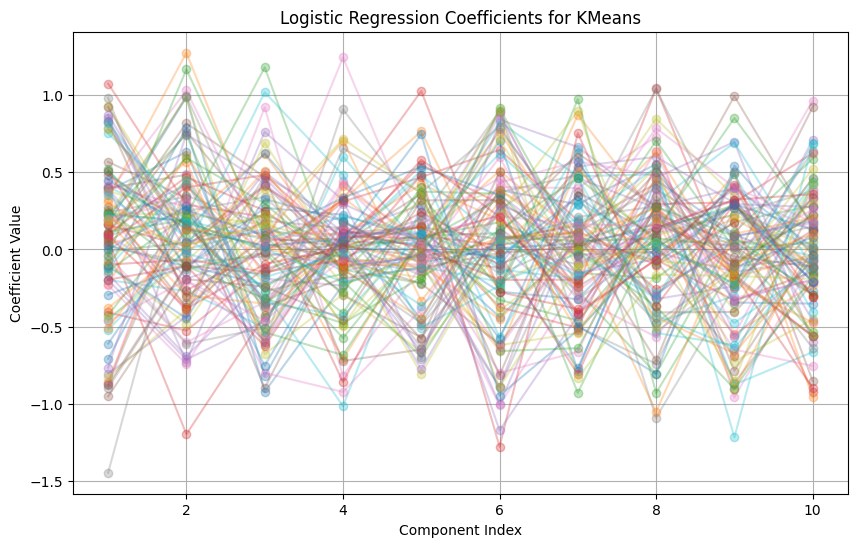

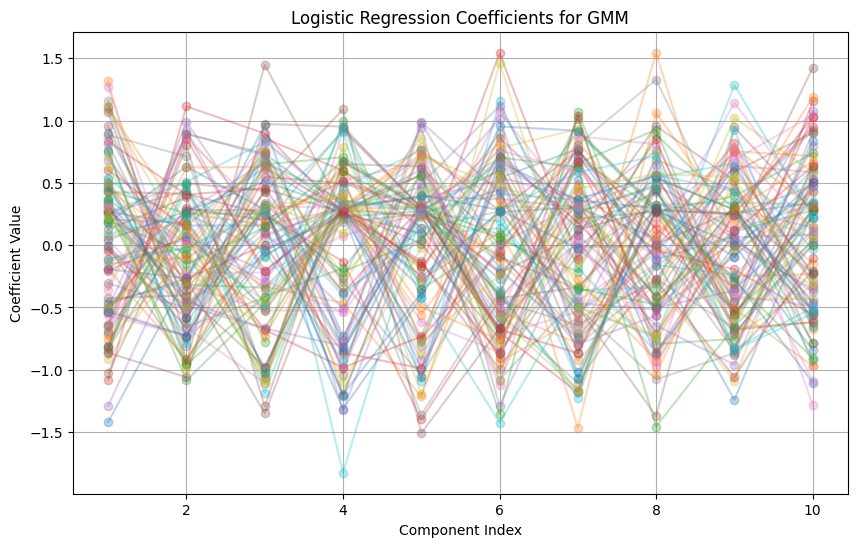

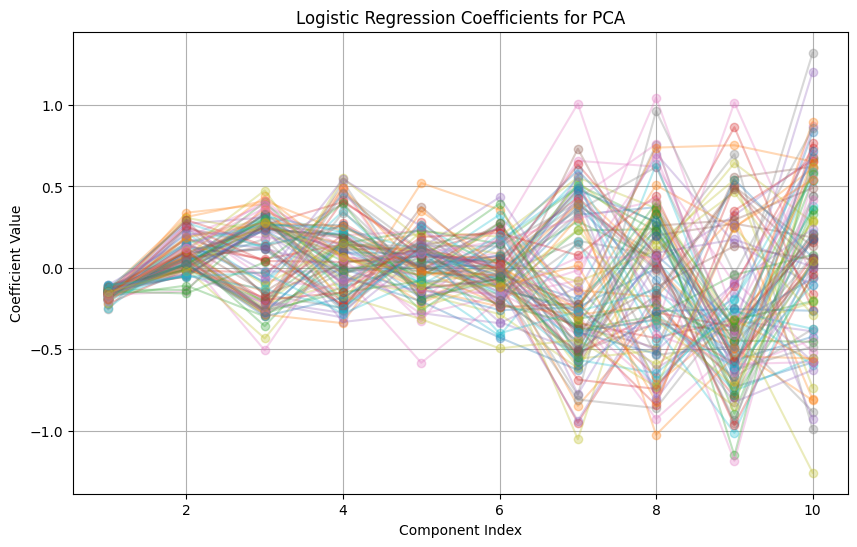

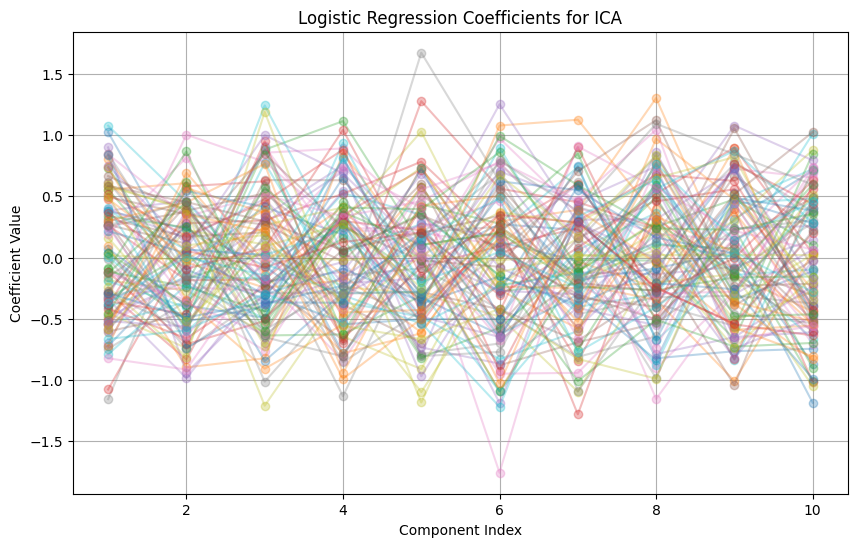

In [5]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA, FastICA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

repeats = 20 
splits_n = 5
n_rois = 100
k = 10
k_means_coefs, gmm_coefs, pca_coefs, ica_coefs = [], [], [], []

input_variables, output_variable = fetch_oasis_dataset(n_rois=n_rois, debug=True)
for repeat in range(repeats):

    kf = KFold(n_splits=splits_n, shuffle=True, random_state=repeat)


    for train_index, test_index in kf.split(input_variables):
        X_train, y_train = input_variables[train_index], output_variable[train_index]
        X_test, y_test = input_variables[test_index], output_variable[test_index]

        lr = LogisticRegression(penalty="l2", C=1.0)

        km = KMeans(n_clusters=k, random_state=repeat)
        lr.fit(km.fit_transform(X_train), y_train)
        k_means_coefs.append(lr.coef_[0])

        gmm = GaussianMixture(n_components=k, random_state=repeat)
        lr.fit(gmm.fit(X_train).predict_proba(X_train), y_train)
        gmm_coefs.append(lr.coef_[0])

        pca = PCA(n_components=k, random_state=repeat)
        lr.fit(pca.fit_transform(X_train), y_train)
        pca_coefs.append(lr.coef_[0])

        ica = FastICA(n_components=k, random_state=repeat)
        lr.fit(ica.fit_transform(X_train), y_train)
        ica_coefs.append(lr.coef_[0])

k_means_coefs = np.array(k_means_coefs)
gmm_coefs = np.array(gmm_coefs)
pca_coefs = np.array(pca_coefs)
ica_coefs = np.array(ica_coefs)


# Function to plot coefficients
def plot_coefficients(coefs, method_name):
    plt.figure(figsize=(10, 6))
    for i in range(coefs.shape[0]):
        plt.plot(range(1, k + 1), coefs[i], marker='o', linestyle='-', alpha=0.3)
    plt.xlabel("Component Index")
    plt.ylabel("Coefficient Value")
    plt.title(f"Logistic Regression Coefficients for {method_name}")
    plt.grid(True)
    plt.show()

# Plot coefficients for each method
plot_coefficients(k_means_coefs, "KMeans")
plot_coefficients(gmm_coefs, "GMM")
plot_coefficients(pca_coefs, "PCA")
plot_coefficients(ica_coefs, "ICA")

Task 5- Same as task 4, but using a different random_state in each cross-validation fold
and a fixed random_state for the dimensionality reduction methods. [think about why and
how this is different from the 4 plots you got from task 5]

Fetched dataset.
input variables shape: (100, 100) 
 output variable shape (100,)


/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGi

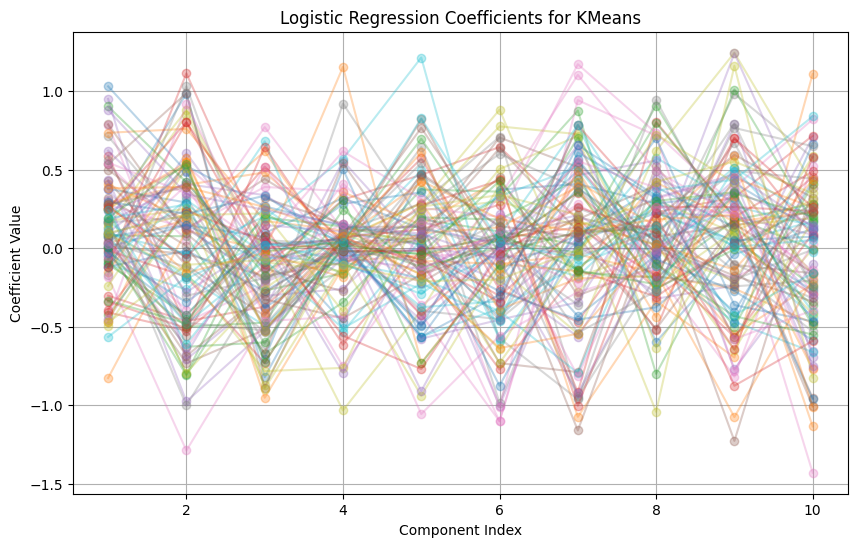

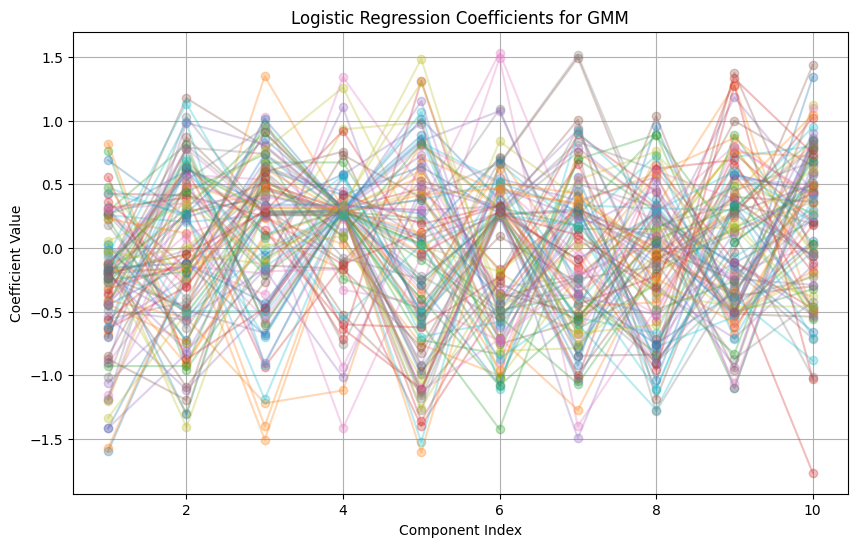

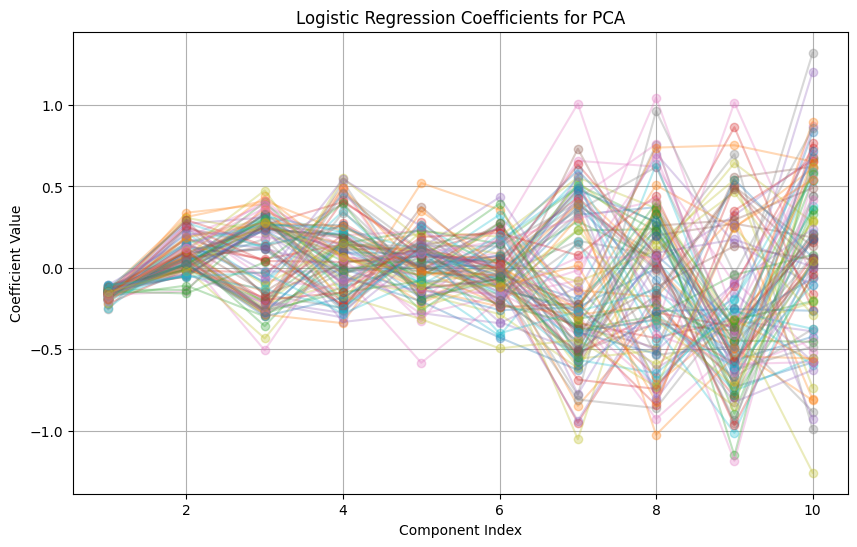

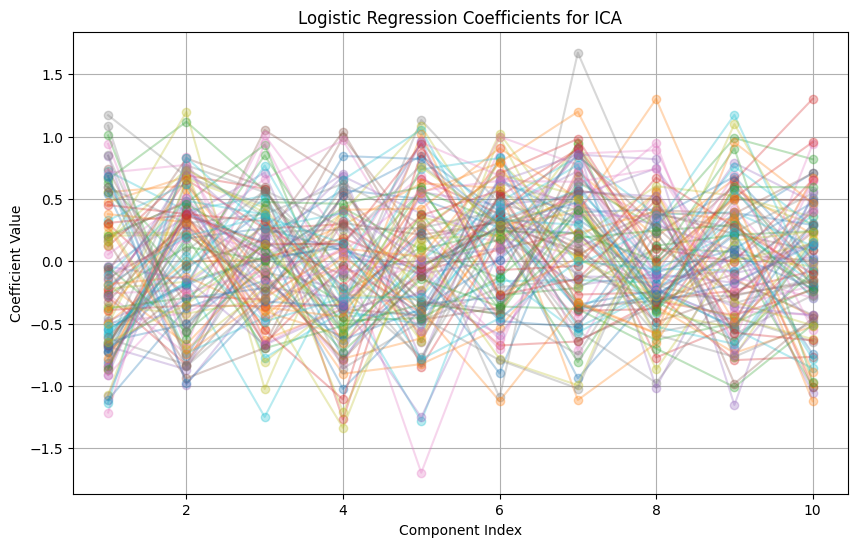

In [6]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA, FastICA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

repeats = 20 
splits_n = 5
n_rois = 100
k = 10
k_means_coefs, gmm_coefs, pca_coefs, ica_coefs = [], [], [], []

input_variables, output_variable = fetch_oasis_dataset(n_rois=n_rois, debug=True)
for repeat in range(repeats):

    kf = KFold(n_splits=splits_n, shuffle=True, random_state=repeat)


    for train_index, test_index in kf.split(input_variables):
        X_train, y_train = input_variables[train_index], output_variable[train_index]
        X_test, y_test = input_variables[test_index], output_variable[test_index]

        lr = LogisticRegression(penalty="l2", C=1.0)

        km = KMeans(n_clusters=k, random_state=0)
        lr.fit(km.fit_transform(X_train), y_train)
        k_means_coefs.append(lr.coef_[0])

        gmm = GaussianMixture(n_components=k, random_state=0)
        lr.fit(gmm.fit(X_train).predict_proba(X_train), y_train)
        gmm_coefs.append(lr.coef_[0])

        pca = PCA(n_components=k, random_state=0)
        lr.fit(pca.fit_transform(X_train), y_train)
        pca_coefs.append(lr.coef_[0])

        ica = FastICA(n_components=k, random_state=0)
        lr.fit(ica.fit_transform(X_train), y_train)
        ica_coefs.append(lr.coef_[0])

k_means_coefs = np.array(k_means_coefs)
gmm_coefs = np.array(gmm_coefs)
pca_coefs = np.array(pca_coefs)
ica_coefs = np.array(ica_coefs)


# Function to plot coefficients
def plot_coefficients(coefs, method_name):
    plt.figure(figsize=(10, 6))
    for i in range(coefs.shape[0]):
        plt.plot(range(1, k + 1), coefs[i], marker='o', linestyle='-', alpha=0.3)
    plt.xlabel("Component Index")
    plt.ylabel("Coefficient Value")
    plt.title(f"Logistic Regression Coefficients for {method_name}")
    plt.grid(True)
    plt.show()

# Plot coefficients for each method
plot_coefficients(k_means_coefs, "KMeans")
plot_coefficients(gmm_coefs, "GMM")
plot_coefficients(pca_coefs, "PCA")
plot_coefficients(ica_coefs, "ICA")

Dataset with brain atlas B: use the Oasis dataset to predict a continuous outcome
(subject’s age) from structural brain scans.

In [7]:
import os 
def load_craddock_local(base_path):
    # Dictionary to hold the dataset information
    craddock_data = {
        'scorr_mean': os.path.join(base_path, 'scorr05_mean_all.nii.gz'),
        'tcorr_mean': os.path.join(base_path, 'tcorr05_mean_all.nii.gz'),
        'scorr_2level': os.path.join(base_path, 'scorr05_2level_all.nii.gz'),
        'tcorr_2level': os.path.join(base_path, 'tcorr05_2level_all.nii.gz'),
        'random': os.path.join(base_path, 'random_all.nii.gz'),
        'description': 'Craddock 2012 atlas parcellation dataset emphasizing spatial and temporal homogeneity.'
    }
    return craddock_data

In [8]:
from nilearn import datasets
from nilearn.input_data import NiftiLabelsMasker
from nilearn.image import index_img
from sklearn.preprocessing import StandardScaler
import nibabel as nib


def fetch_second_dataset(n_rois, debug=False):

    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)

    brain_data_dir = "/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/A3/craddock/"
    crad = load_craddock_local(brain_data_dir)

    atlas_nii = index_img(crad["scorr_mean"], n_rois)
    masker = NiftiLabelsMasker(labels_img=atlas_nii, standardize=True)
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = StandardScaler().fit_transform(brain_data.ext_vars.age[:, None])[
        :, 0
    ]  # gives subject age on standard units after z-scoring
    return input_variables, output_variable

6- analogous to task 1

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE5

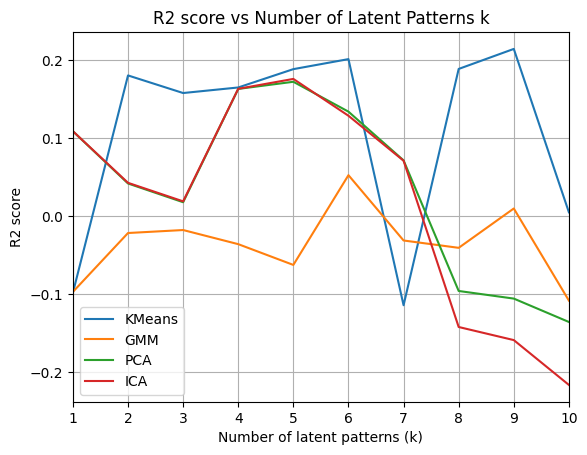

In [9]:
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.decomposition import PCA, FastICA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import numpy as np 


splits_n = 5
n_rois = 0
ks = range(1, 11)
k_means_res, gmm_res, pca_res, ica_res = [], [], [], []

input_variables, output_variable = fetch_second_dataset(n_rois=n_rois)
kf = KFold(n_splits=splits_n, shuffle=True)

for k in ks:
    k_means_acc, gmm_acc, pca_acc, ica_acc = [], [], [], []

    for train_index, test_index in kf.split(input_variables):
        X_train, y_train = input_variables[train_index], output_variable[train_index]
        X_test, y_test = input_variables[test_index], output_variable[test_index]

        lr = Ridge()

        km = KMeans(n_clusters=k)
        lr.fit(km.fit_transform(X_train), y_train)
        k_means_acc.append(r2_score(y_test, lr.predict(km.transform(X_test))))

        gmm = GaussianMixture(n_components=k)
        lr.fit(gmm.fit_predict(X_train).reshape(-1, 1), y_train)
        gmm_acc.append(
            r2_score(y_test, lr.predict(gmm.predict(X_test).reshape(-1, 1)))
        )

        pca = PCA(n_components=k)
        lr.fit(pca.fit_transform(X_train), y_train)
        pca_acc.append(r2_score(y_test, lr.predict(pca.transform(X_test))))

        ica = FastICA(n_components=k, random_state=42)
        lr.fit(ica.fit_transform(X_train), y_train)
        ica_acc.append(r2_score(y_test, lr.predict(ica.transform(X_test))))

    k_means_res.append(np.mean(k_means_acc))
    gmm_res.append(np.mean(gmm_acc))
    pca_res.append(np.mean(pca_acc))
    ica_res.append(np.mean(ica_acc))

plt.figure()
plt.plot(list(ks), k_means_res, label="KMeans")
plt.plot(list(ks), gmm_res, label="GMM")
plt.plot(list(ks), pca_res, label="PCA")
plt.plot(list(ks), ica_res, label="ICA")
plt.xlabel("Number of latent patterns (k)")
plt.ylabel("R2 score")
plt.title("R2 score vs Number of Latent Patterns k")
plt.legend()
plt.grid(True)
plt.xticks(list(ks))
plt.xlim([1, 10])
plt.show()


note the in the plot above, pca and ica overlap. 

7- analogous to task 2

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE5

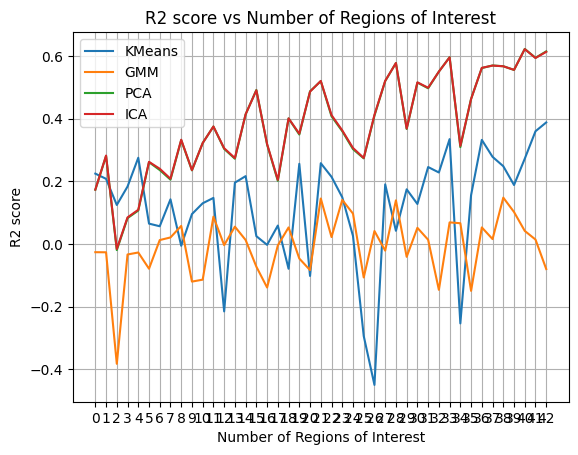

In [10]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA, FastICA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

splits_n = 5
n_rois = range(0, 43)
k = 5
k_means_res, gmm_res, pca_res, ica_res = [], [], [], []

for n_roi in n_rois:
    k_means_acc, gmm_acc, pca_acc, ica_acc = [], [], [], []

    input_variables, output_variable = fetch_second_dataset(n_rois=n_roi)
    kf = KFold(n_splits=splits_n, shuffle=True)


    for train_index, test_index in kf.split(input_variables):
        X_train, y_train = input_variables[train_index], output_variable[train_index]
        X_test, y_test = input_variables[test_index], output_variable[test_index]

        lr = Ridge()

        km = KMeans(n_clusters=k)
        lr.fit(km.fit_transform(X_train), y_train)
        k_means_acc.append(r2_score(y_test, lr.predict(km.transform(X_test))))

        gmm = GaussianMixture(n_components=k)
        lr.fit(gmm.fit_predict(X_train).reshape(-1, 1), y_train)
        gmm_acc.append(
            r2_score(y_test, lr.predict(gmm.predict(X_test).reshape(-1, 1)))
        )

        pca = PCA(n_components=k)
        lr.fit(pca.fit_transform(X_train), y_train)
        pca_acc.append(r2_score(y_test, lr.predict(pca.transform(X_test))))

        ica = FastICA(n_components=k, random_state=42)
        lr.fit(ica.fit_transform(X_train), y_train)
        ica_acc.append(r2_score(y_test, lr.predict(ica.transform(X_test))))

    k_means_res.append(np.mean(k_means_acc))
    gmm_res.append(np.mean(gmm_acc))
    pca_res.append(np.mean(pca_acc))
    ica_res.append(np.mean(ica_acc))

plt.figure()
plt.plot(list(n_rois), k_means_res, label="KMeans")
plt.plot(list(n_rois), gmm_res, label="GMM")
plt.plot(list(n_rois), pca_res, label="PCA")
plt.plot(list(n_rois), ica_res, label="ICA")
plt.xlabel("Number of Regions of Interest")
plt.ylabel("R2 score")
plt.title("R2 score vs Number of Regions of Interest")
plt.legend()
plt.grid(True)
plt.xticks(list(n_rois))
plt.show()


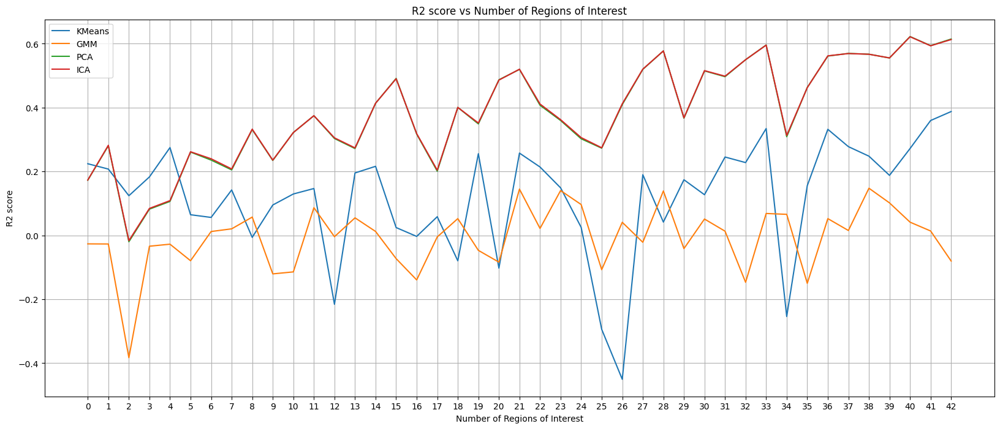

In [12]:
plt.figure(figsize=(20, 8))
plt.plot(list(n_rois), k_means_res, label="KMeans")
plt.plot(list(n_rois), gmm_res, label="GMM")
plt.plot(list(n_rois), pca_res, label="PCA")
plt.plot(list(n_rois), ica_res, label="ICA")
plt.xlabel("Number of Regions of Interest")
plt.ylabel("R2 score")
plt.title("R2 score vs Number of Regions of Interest")
plt.legend()
plt.grid(True)
plt.xticks(list(n_rois))
plt.show()


8- analogous to task 3

In [13]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA, FastICA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import tqdm

splits_n = 5
n_rois = range(43)

ks = range(1, 11)

k_means_res, gmm_res, pca_res, ica_res = [], [], [], []
k_means_res_train, gmm_res_train, pca_res_train, ica_res_train = [], [], [], []

for k in tqdm.tqdm(ks, desc="outer loop"):
    for n_roi in tqdm.tqdm(n_rois, desc="middle loop"):
        input_variables, output_variable = fetch_second_dataset(n_rois=n_roi)
        kf = KFold(n_splits=splits_n, shuffle=True)

        k_means_acc, gmm_acc, pca_acc, ica_acc = [], [], [], []
        k_means_acc_train, gmm_acc_train, pca_acc_train, ica_acc_train = [], [], [], []
        for train_index, test_index in kf.split(input_variables):
            X_train, y_train = (
                input_variables[train_index],
                output_variable[train_index],
            )
            X_test, y_test = input_variables[test_index], output_variable[test_index]

            lr = Ridge()

            km = KMeans(n_clusters=k)
            lr.fit(km.fit_transform(X_train), y_train)
            k_means_acc.append(r2_score(y_test, lr.predict(km.transform(X_test))))
            k_means_acc_train.append(
                r2_score(y_train, lr.predict(km.transform(X_train)))
            )

            gmm = GaussianMixture(n_components=k)
            lr.fit(gmm.fit_predict(X_train).reshape(-1, 1), y_train)
            gmm_acc.append(
                r2_score(y_test, lr.predict(gmm.predict(X_test).reshape(-1, 1)))
            )
            gmm_acc_train.append(r2_score(y_train, lr.predict(gmm.predict(X_train).reshape(-1, 1))))

            pca = PCA(n_components=k)
            lr.fit(pca.fit_transform(X_train), y_train)
            pca_acc.append(r2_score(y_test, lr.predict(pca.transform(X_test))))
            pca_acc_train.append(r2_score(y_train, lr.predict(pca.transform(X_train))))

            ica = FastICA(n_components=k)
            lr.fit(ica.fit_transform(X_train), y_train)
            ica_acc.append(r2_score(y_test, lr.predict(ica.transform(X_test))))
            ica_acc_train.append(r2_score(y_train, lr.predict(ica.transform(X_train))))

        k_means_res.append(np.mean(k_means_acc))
        gmm_res.append(np.mean(gmm_acc))
        pca_res.append(np.mean(pca_acc))
        ica_res.append(np.mean(ica_acc))
        k_means_res_train.append(np.mean(k_means_acc_train))
        gmm_res_train.append(np.mean(gmm_acc_train))
        pca_res_train.append(np.mean(pca_acc_train))
        ica_res_train.append(np.mean(ica_acc_train))

outer loop:  10%|█         | 1/10 [09:16<1:23:30, 556.70s/it]/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan

/tmp/ipykernel_34264/3997480771.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(n_rois))
/tmp/ipykernel_34264/3997480771.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(ks))


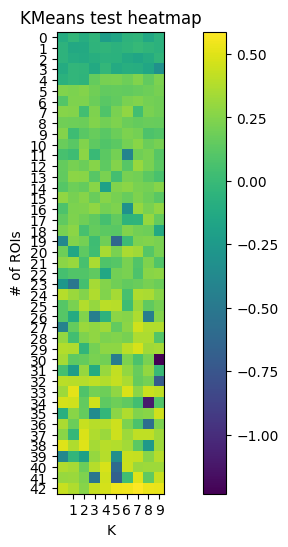

/tmp/ipykernel_34264/3997480771.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(n_rois))
/tmp/ipykernel_34264/3997480771.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(ks))


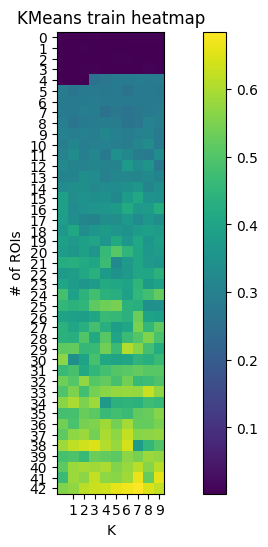

/tmp/ipykernel_34264/3997480771.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(n_rois))
/tmp/ipykernel_34264/3997480771.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(ks))


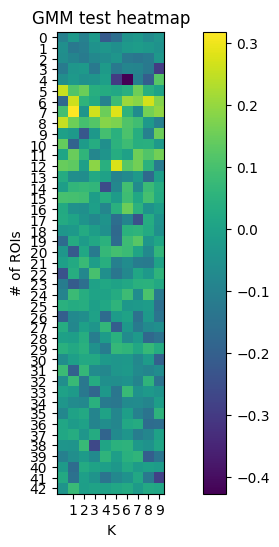

/tmp/ipykernel_34264/3997480771.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(n_rois))
/tmp/ipykernel_34264/3997480771.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(ks))


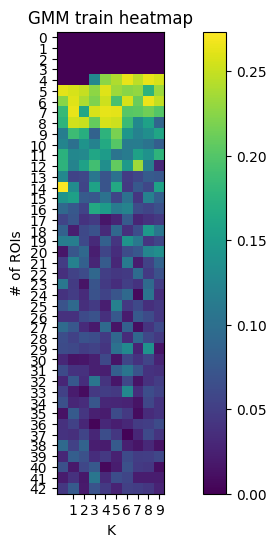

/tmp/ipykernel_34264/3997480771.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(n_rois))
/tmp/ipykernel_34264/3997480771.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(ks))


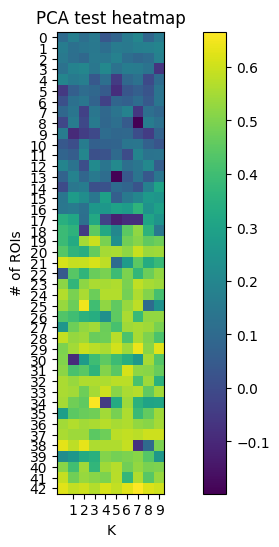

/tmp/ipykernel_34264/3997480771.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(n_rois))
/tmp/ipykernel_34264/3997480771.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(ks))


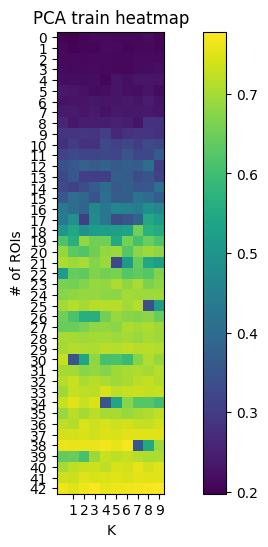

/tmp/ipykernel_34264/3997480771.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(n_rois))
/tmp/ipykernel_34264/3997480771.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(ks))


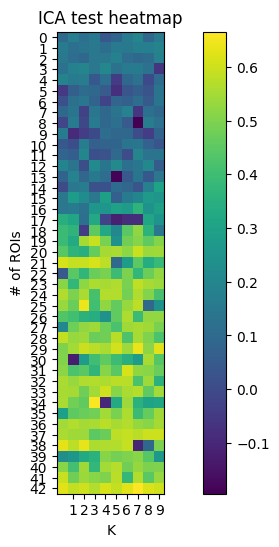

/tmp/ipykernel_34264/3997480771.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(list(n_rois))
/tmp/ipykernel_34264/3997480771.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(ks))


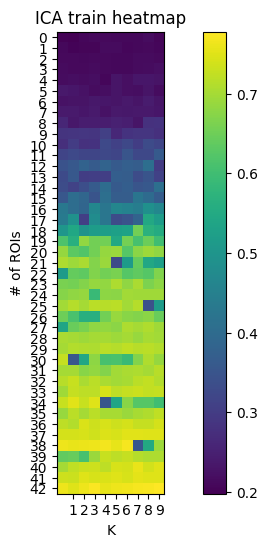

In [27]:
def plot_square_heatmap(data, title):
    # Determine the size of the square matrix
    n = int(len(data) ** 0.5)
        
    # Reshape data into an n x n matrix
    matrix = np.array(data).reshape(43, 10)
    # Plot heatmap
    plt.figure(figsize=(10, 6))
    ax = plt.axes() 
    ax.set_yticklabels(list(n_rois))
    ax.set_xticklabels(list(ks))
    ax.set_xticks(list(ks))
    ax.set_yticks(list(n_rois))
    plt.xlabel("K")
    plt.ylabel("# of ROIs")
    plt.imshow(matrix, cmap='viridis', interpolation='nearest')
    plt.colorbar()
    plt.title(title)
    plt.show()


n_rois = range(43)
ks = range(1, 11)

plot_square_heatmap(k_means_res, "KMeans test heatmap")
plot_square_heatmap(k_means_res_train, "KMeans train heatmap")
plot_square_heatmap(gmm_res, "GMM test heatmap")
plot_square_heatmap(gmm_res_train, "GMM train heatmap")
plot_square_heatmap(pca_res, "PCA test heatmap")
plot_square_heatmap(pca_res_train, "PCA train heatmap")
plot_square_heatmap(ica_res, "ICA test heatmap")
plot_square_heatmap(ica_res_train, "ICA train heatmap")

9- analogous to task 4

In [17]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA, FastICA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

repeats = 20 
splits_n = 5
n_rois = 0
k = 10
k_means_coefs, gmm_coefs, pca_coefs, ica_coefs = [], [], [], []

input_variables, output_variable = fetch_second_dataset(n_rois=n_rois)
for repeat in range(repeats):

    kf = KFold(n_splits=splits_n, shuffle=True, random_state=repeat)


    for train_index, test_index in kf.split(input_variables):
        X_train, y_train = input_variables[train_index], output_variable[train_index]
        X_test, y_test = input_variables[test_index], output_variable[test_index]

        lr = Ridge()

        km = KMeans(n_clusters=k, random_state=repeat)
        lr.fit(km.fit_transform(X_train), y_train)
        k_means_coefs.append(lr.coef_)

        gmm = GaussianMixture(n_components=k, random_state=repeat)
        lr.fit(gmm.fit(X_train).predict_proba(X_train), y_train)
        gmm_coefs.append(lr.coef_)

        pca = PCA(n_components=k, random_state=repeat)
        lr.fit(pca.fit_transform(X_train), y_train)
        pca_coefs.append(lr.coef_)

        ica = FastICA(n_components=k, random_state=repeat)
        lr.fit(ica.fit_transform(X_train), y_train)
        ica_coefs.append(lr.coef_)

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE5

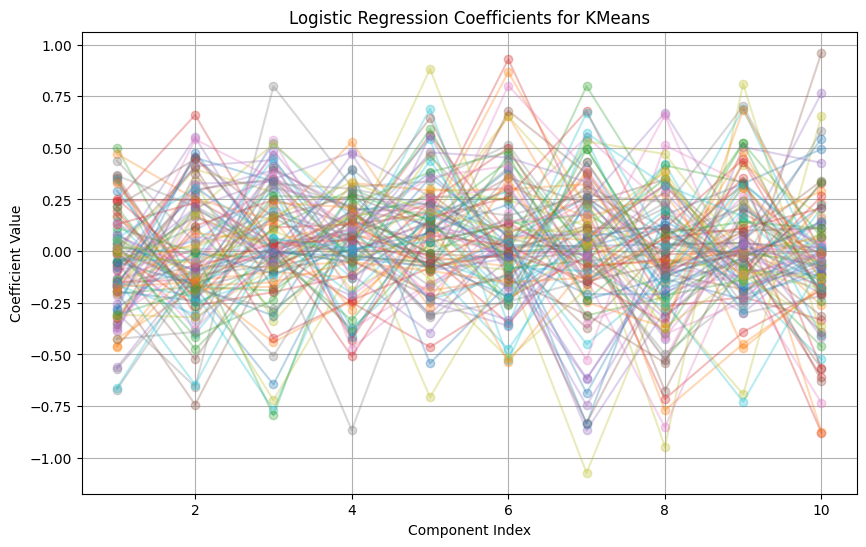

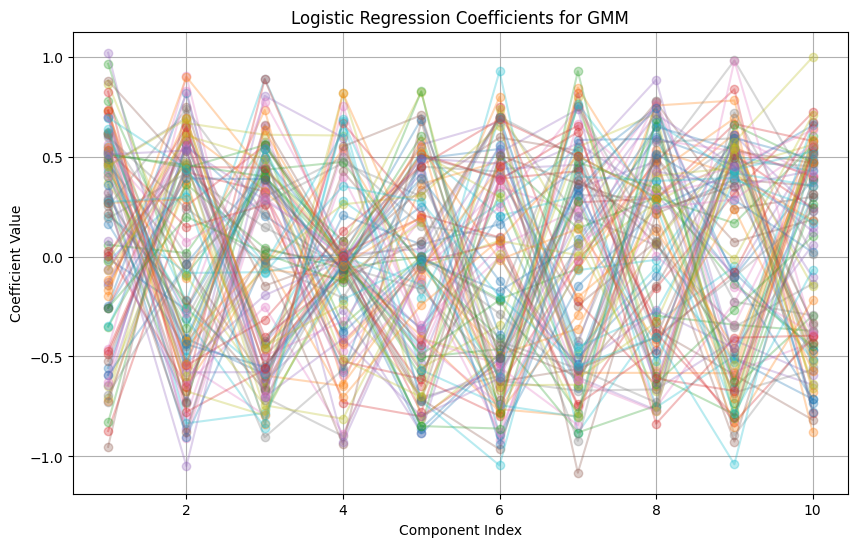

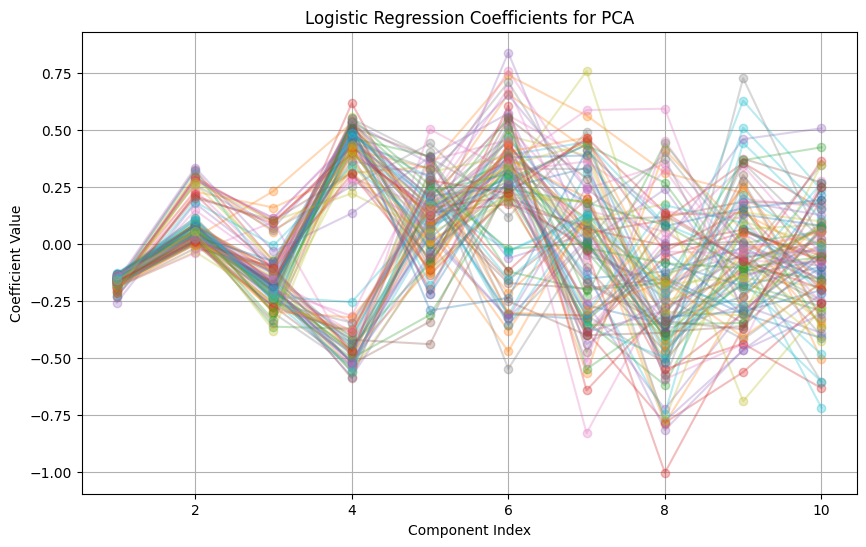

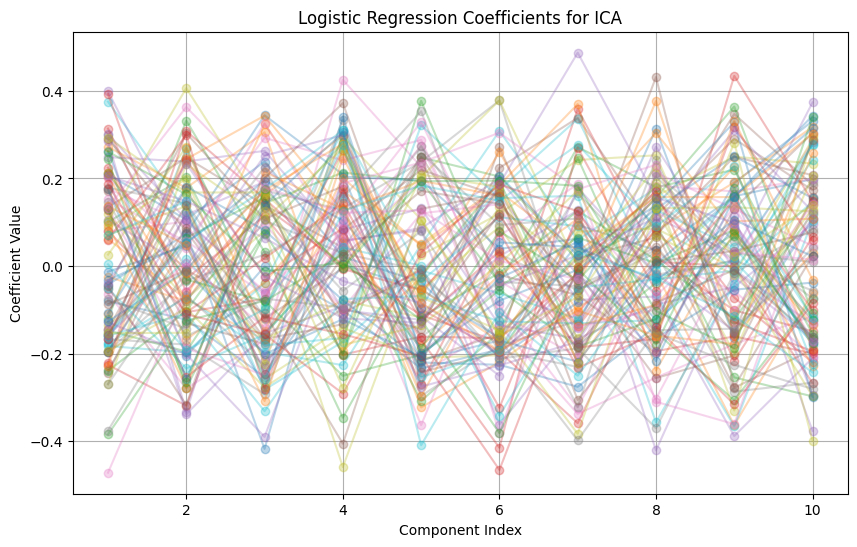

In [18]:
k_means_coefs = np.array(k_means_coefs)
gmm_coefs = np.array(gmm_coefs)
pca_coefs = np.array(pca_coefs)
ica_coefs = np.array(ica_coefs)


# Function to plot coefficients
def plot_coefficients(coefs, method_name):
    plt.figure(figsize=(10, 6))
    for i in range(coefs.shape[0]):
        plt.plot(range(1, k + 1), coefs[i], marker='o', linestyle='-', alpha=0.3)
    plt.xlabel("Component Index")
    plt.ylabel("Coefficient Value")
    plt.title(f"Logistic Regression Coefficients for {method_name}")
    plt.grid(True)
    plt.show()

# Plot coefficients for each method
plot_coefficients(k_means_coefs, "KMeans")
plot_coefficients(gmm_coefs, "GMM")
plot_coefficients(pca_coefs, "PCA")
plot_coefficients(ica_coefs, "ICA")

10- analogous to task 5

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/decomposition/_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE5

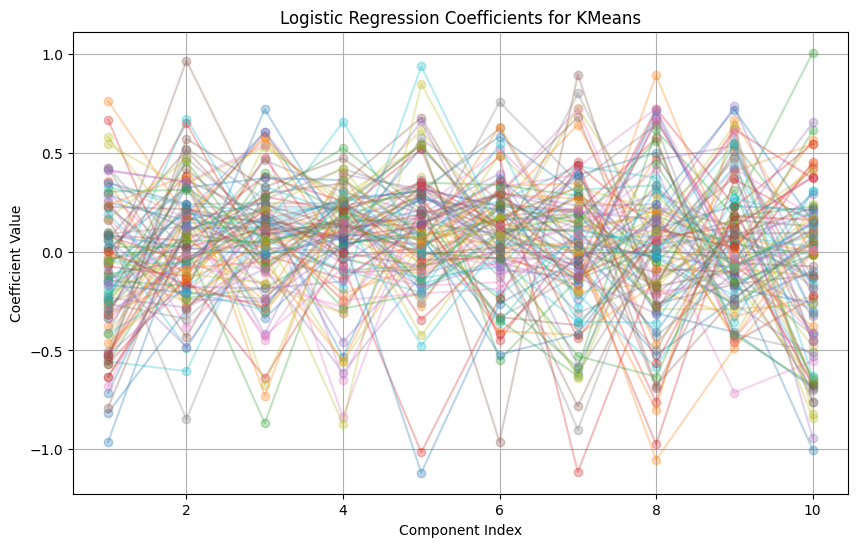

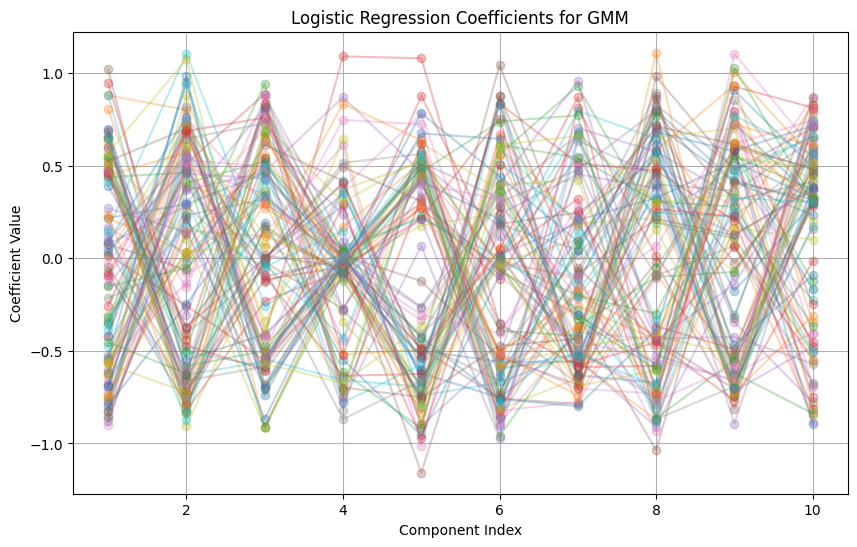

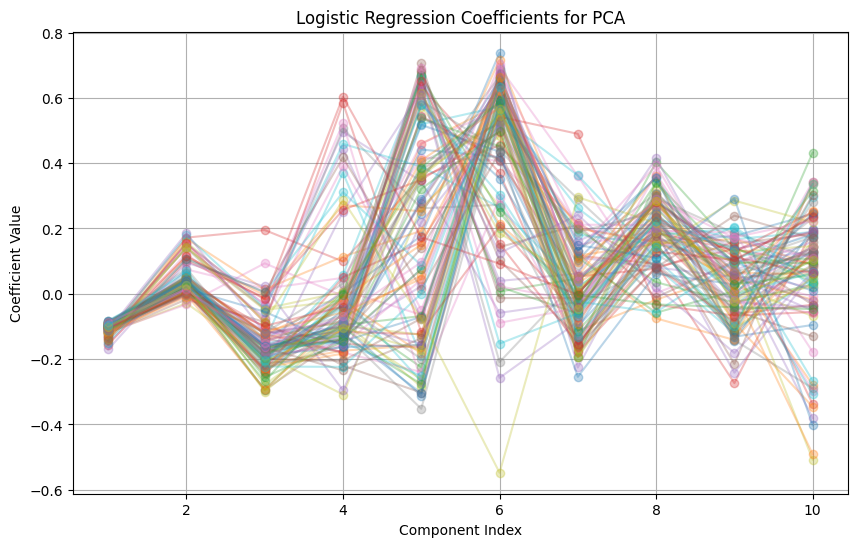

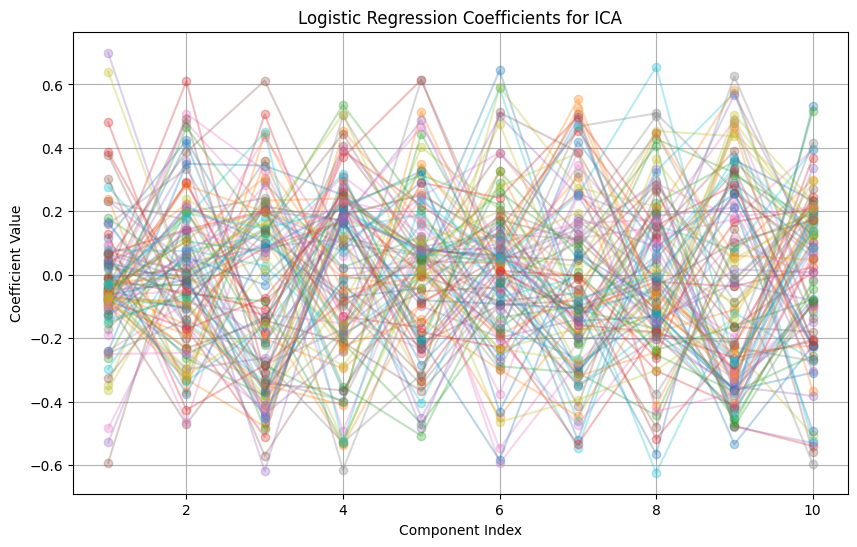

In [19]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA, FastICA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

repeats = 20 
splits_n = 5
n_rois = 2
k = 10
k_means_coefs, gmm_coefs, pca_coefs, ica_coefs = [], [], [], []

input_variables, output_variable = fetch_second_dataset(n_rois=n_rois, debug=True)
for repeat in range(repeats):

    kf = KFold(n_splits=splits_n, shuffle=True, random_state=repeat)


    for train_index, test_index in kf.split(input_variables):
        X_train, y_train = input_variables[train_index], output_variable[train_index]
        X_test, y_test = input_variables[test_index], output_variable[test_index]

        lr = Ridge()

        km = KMeans(n_clusters=k, random_state=0)
        lr.fit(km.fit_transform(X_train), y_train)
        k_means_coefs.append(lr.coef_)

        gmm = GaussianMixture(n_components=k, random_state=0)
        lr.fit(gmm.fit(X_train).predict_proba(X_train), y_train)
        gmm_coefs.append(lr.coef_)

        pca = PCA(n_components=k, random_state=0)
        lr.fit(pca.fit_transform(X_train), y_train)
        pca_coefs.append(lr.coef_)

        ica = FastICA(n_components=k, random_state=0)
        lr.fit(ica.fit_transform(X_train), y_train)
        ica_coefs.append(lr.coef_)

k_means_coefs = np.array(k_means_coefs)
gmm_coefs = np.array(gmm_coefs)
pca_coefs = np.array(pca_coefs)
ica_coefs = np.array(ica_coefs)


# Function to plot coefficients
def plot_coefficients(coefs, method_name):
    plt.figure(figsize=(10, 6))
    for i in range(coefs.shape[0]):
        plt.plot(range(1, k + 1), coefs[i], marker='o', linestyle='-', alpha=0.3)
    plt.xlabel("Component Index")
    plt.ylabel("Coefficient Value")
    plt.title(f"Logistic Regression Coefficients for {method_name}")
    plt.grid(True)
    plt.show()

# Plot coefficients for each method
plot_coefficients(k_means_coefs, "KMeans")
plot_coefficients(gmm_coefs, "GMM")
plot_coefficients(pca_coefs, "PCA")
plot_coefficients(ica_coefs, "ICA")